<a href="https://colab.research.google.com/github/Amal1703/AI_ML_football/blob/main/stage_1_train_YOLO_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Turn on GPU acceleration

In [ ]:
# In Colab:
# Click Runtime
# Then click Change runtime type
# Under Hardware accelerator, select GPU T4
# Click Save

# Install libraires

In [ ]:
!pip install roboflow
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.4/322.4 kB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 74.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 6.1 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.2
    Uninstalling typer-0.27.2:
      Successfully uninstalled typer-0.27.2
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 24.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 kB 9.0 MB/s eta 0:00:00


In [ ]:
from roboflow import Roboflow
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


# Download dataset

In [ ]:
# Download the dataset from Roboflow (yolov11)
# 1. from https://universe.roboflow.com/roboflow-jvuqo/football-players-detection-3zvbc/dataset/20
# 2. ON Popular Download Formats, cliqu on yolov1
# 3. clic on Download dataset and copy the python code (code au dessous) to dwonlod data

rf = Roboflow(api_key="waNECdEukH3W2rtXwlET")
project = rf.workspace("roboflow-jvuqo").project("football-players-detection-3zvbc")
version = project.version(20)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to football-players-detection-20 in yolov11:: 100%|██████████| 756/756 [00:00<00:00, 4609.06it/s]


# Train yolo 11 model

In [ ]:
!yolo task=detect mode=train data={dataset.location}/data.yaml model=yolo11n.pt epochs=140 imgsz=640 val=True patience=15

Ultralytics 8.4.157 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/football-players-detection-20/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=140, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, op

# test data


In [ ]:
import glob
from IPython.display import Image

# A class that predicts images by running a trained YOLO model and displays the predicted images
class Test_model_and_disp_img:

# Class attribute shared by all instances (static variable)
    results = None

# Function to predict images by running a YOLO trained model and save them
# source: path to the folder containing test images
# project: path to the folder that contains predicted images
# model: path to the trained model to load
    def Test_model (self, model_path, source, project):
        model = YOLO(model_path)
        self.results = model.predict(
            source=source,
            project=project,
            conf=0.5,        # Confidence threshold (only show > 50%) : The conf ensures only predictions with > 50% confidence are shown/saved.
            save=True
        )

# Function to display the predicted images
# nb_image_to_visualise: number of predicted images to display
    def display_pred_images (self, nb_image_to_visualise):
       image_paths = glob.glob(os.path.join(self.results[0].save_dir, "*.jpg"))
       for i, image_path in enumerate(image_paths[:nb_image_to_visualise]):
         print("Image number", i+1)
         display(Image(filename=image_path, height=400))
         print("\n")

In [ ]:
# Create an instance of Test_model_and_disp_img
test_model_and_disp_img = Test_model_and_disp_img()


image 1/25 /content/football-players-detection-20/test/images/08fd33_3_6_png.rf.261781c58b95436fb40e6afc0495bc57.jpg: 640x640 2 balls, 22 players, 3 referees, 7.9ms
image 2/25 /content/football-players-detection-20/test/images/08fd33_9_3_png.rf.20ff5bcc914d7f607cf9425c73da679c.jpg: 640x640 24 players, 1 referee, 8.1ms
image 3/25 /content/football-players-detection-20/test/images/40cd38_7_6_png.rf.3e49856b19208cd7b616cd826a793f08.jpg: 640x640 1 ball, 1 goalkeeper, 22 players, 1 referee, 8.1ms
image 4/25 /content/football-players-detection-20/test/images/42ba34_1_5_png.rf.e530a34d1588130dae6f6cba815688ce.jpg: 640x640 1 ball, 1 goalkeeper, 26 players, 1 referee, 8.4ms
image 5/25 /content/football-players-detection-20/test/images/42ba34_5_5_png.rf.4153d27549bb9aad06d11a54c1ea3dc3.jpg: 640x640 1 goalkeeper, 22 players, 1 referee, 11.4ms
image 6/25 /content/football-players-detection-20/test/images/4b770a_1_4_png.rf.746881815061da6082d636894dbb523f.jpg: 640x640 1 goalkeeper, 21 players, 3 r

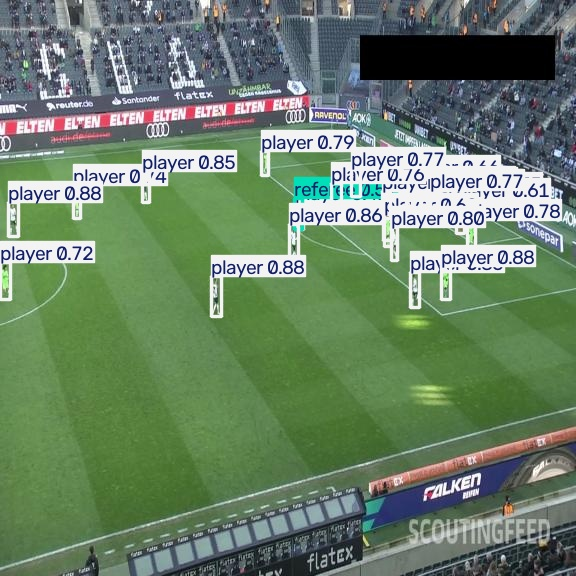



Image number 2


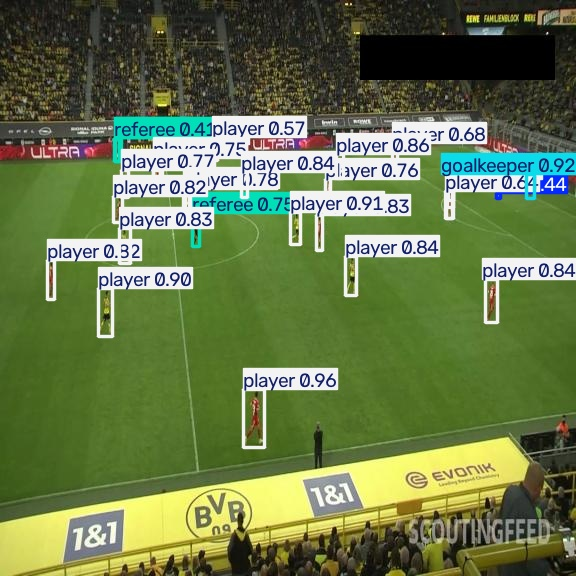



Image number 3


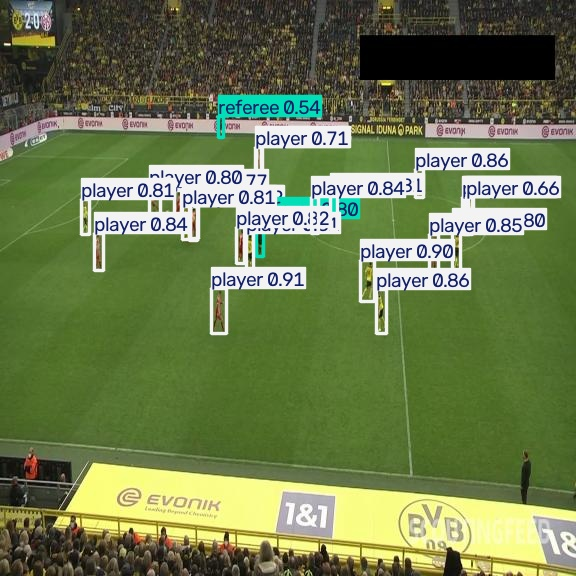



Image number 4


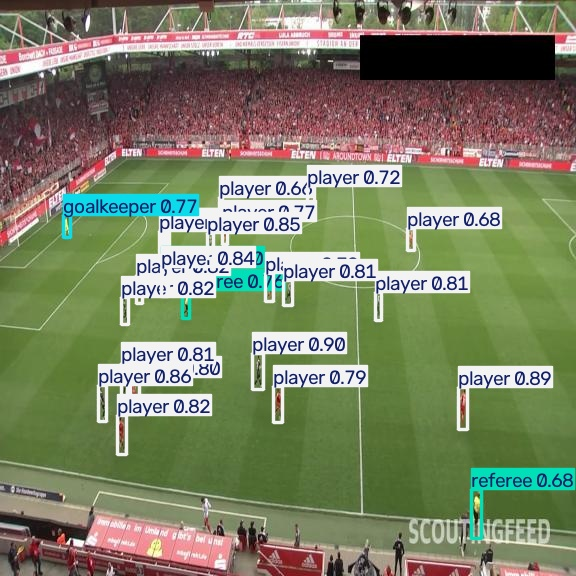



Image number 5


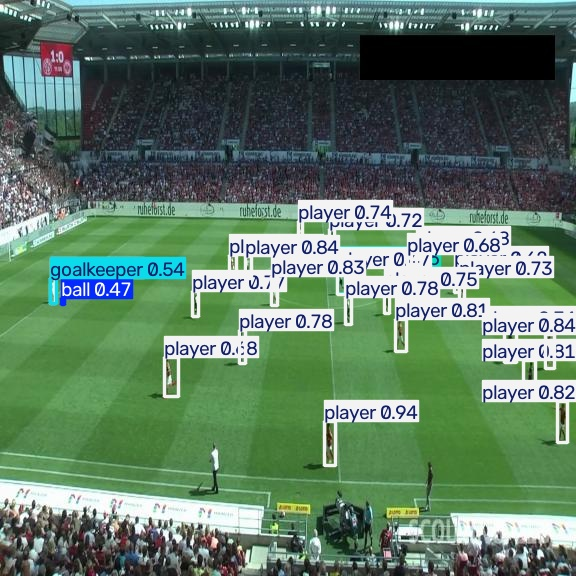



Image number 6


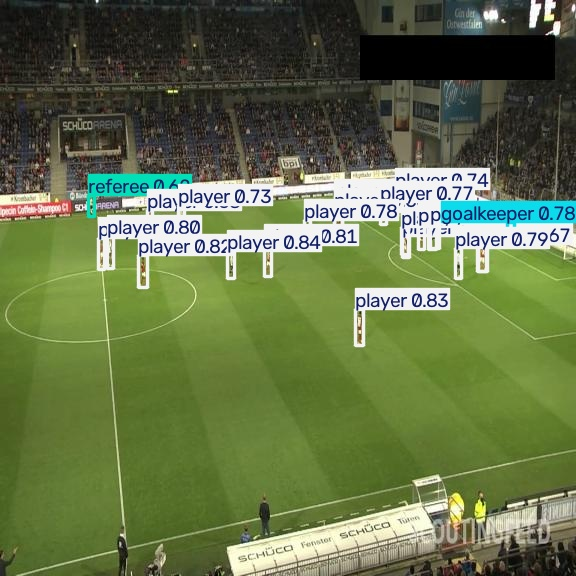



Image number 7


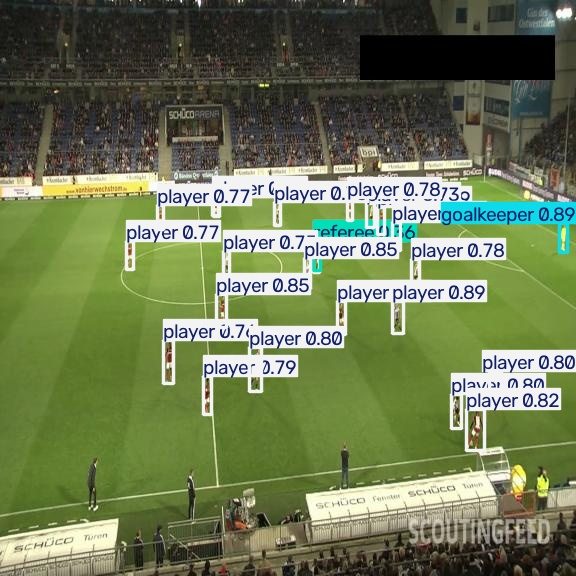



Image number 8


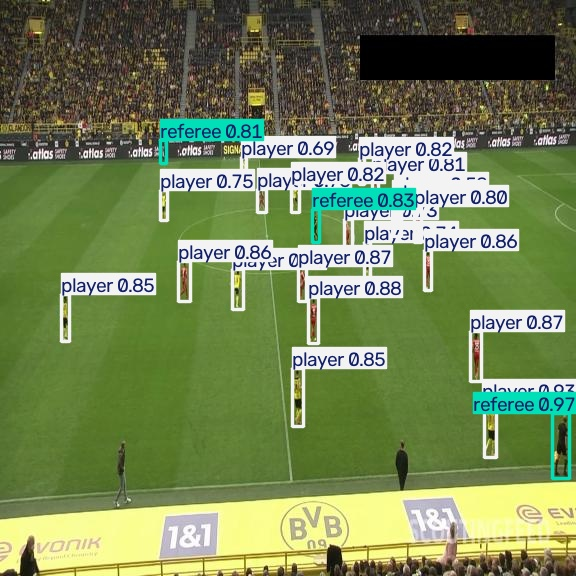



Image number 9


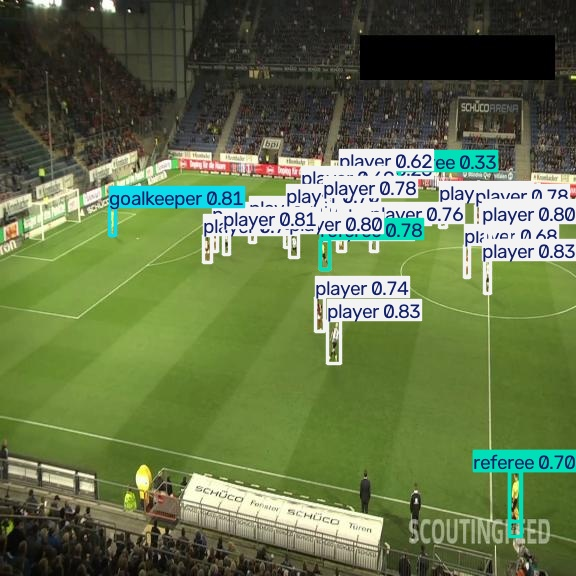



Image number 10


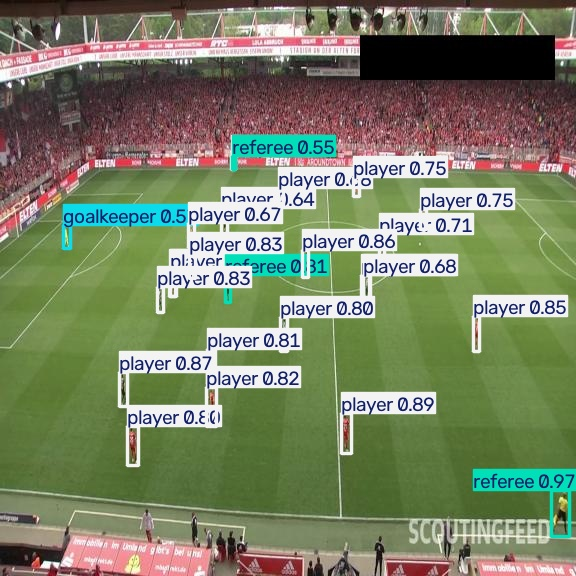



Image number 11


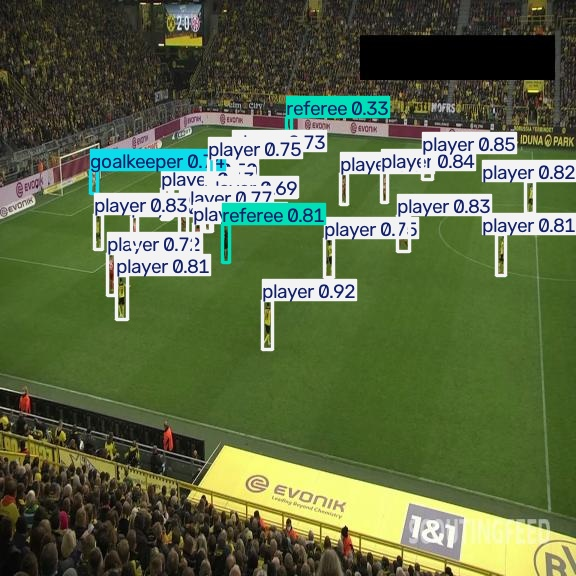



Image number 12


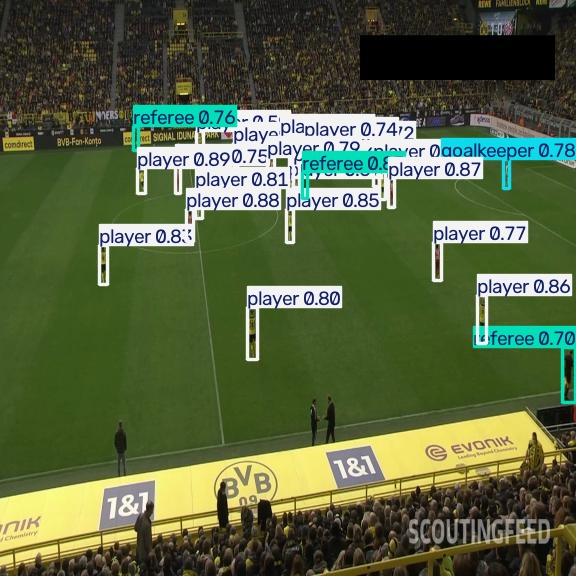



Image number 13


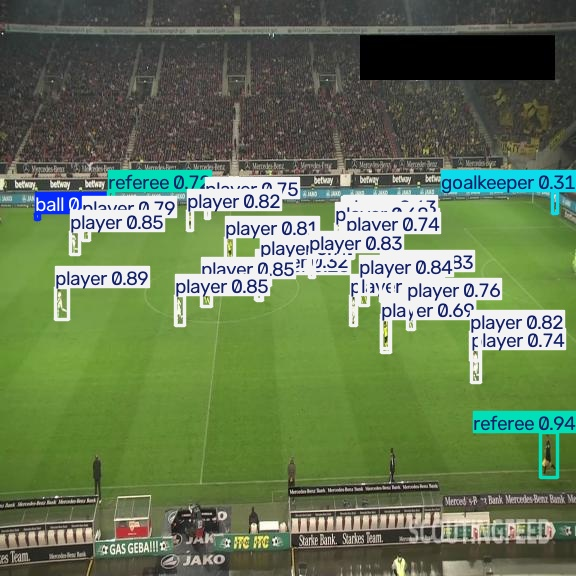



Image number 14


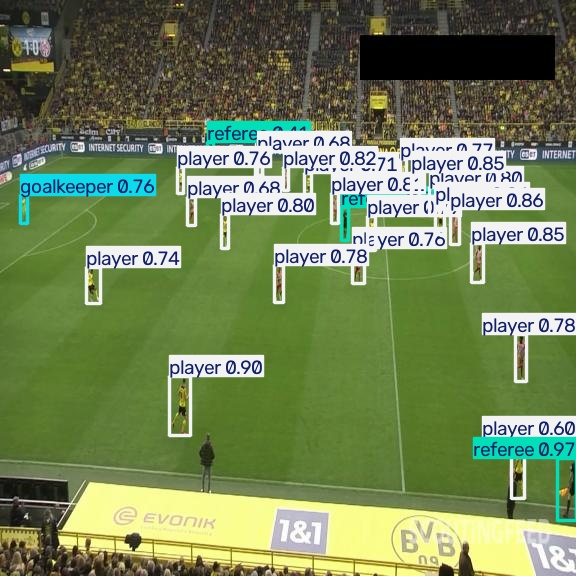



Image number 15


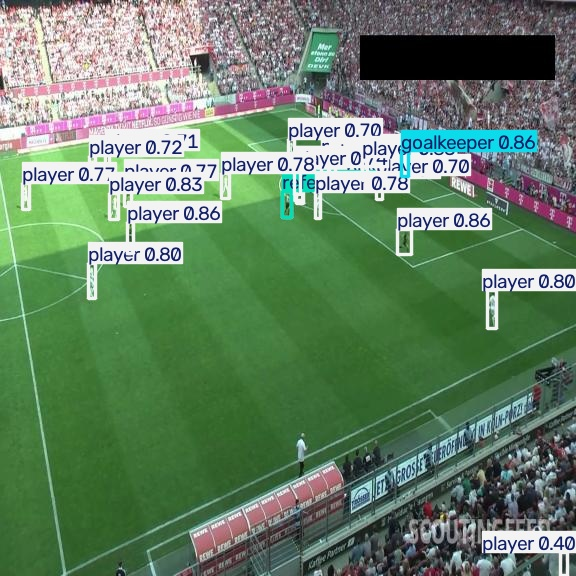

In [ ]:
# Loads YOLO model, predicts 1st class test images, and displays results
test_model_and_disp_img.Test_model("/content/runs/detect/train/weights/best.pt",
                                  "/content/football-players-detection-20/test/images",
                                  "/content/football-players-test")

test_model_and_disp_img.display_pred_images (15)

# download //content/runs/detect/train/weights/best.pt et mettre dans dossier de travail

# download //content/runs/detect/train/weights/last.pt et mettre dans dossier de travail